# Ingestão e análise - Antecipação de Recebíveis da Olist

O objetivo desse mini-projeto é aplicar os conceitos de **Engenharia e Análise de Dados** para estudo e construção de portfólio.\
Abaixo um pipeline de dados (camadas **bronze → silver → gold**) foi montado completamente usando os recursos do Databricks com scripts em **Python, PySpark e SQL**.\
\
**Dataset utilizado**: Kaggle -  [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## Regras de negócio

Não são premissas de mercado (taxas, MDR, custo de captação de dinheiro): são regras de construção da agenda e cortes da segmentação. Ficam aqui para que nenhum número apareça "solto" no código.

In [0]:
# Agenda: a parcela k de uma venda no crédito liquida em D + 30·k.
PRAZO_DIAS_PARCELA = 30

# Segmentação por regra (Etapa 3). Ajuste depois de olhar as distribuições e registre o motivo.
SEG_TOP_AGENDA = 0.20 # top 20% dos lojistas por agenda em aberto
SEG_MIN_PARCELADO = 0.50 # > 50% do TPV no crédito parcelado = "grande parcelador"
SEG_MAX_PARCELADO_AVISTA = 0.20 # < 20% do TPV parcelado = "à vista"
SEG_MIN_MESES_ATIVOS = 3 # vendas em pelo menos 3 meses...
SEG_JANELA_MESES = 6 # ...dos últimos 6 meses até a data de corte
# 5º segmento, aberto após o k-means (seção 6.6 do notebook 06) mostrar que "Pequenos ou
# esporádicos" misturava dois perfis: o cluster "prazo longo · ticket alto" tem venda grande,
# parcelada e com espera longa (~4 meses), mas sem recorrência — não merece o rótulo "pequeno".
SEG_MIN_PRAZO_OCASIONAIS = 90 # prazo médio contratado >= 90 dias (~3+ parcelas) = "grande ocasional"

# K-means
KMEANS_MIN_PEDIDOS = 3 # lojistas com menos pedidos geram ruído no agrupamento
KMEANS_K_RANGE = range(2, 9)
KMEANS_SEED = 42


## View de parâmetros para as células SQL

As células `%sql` leem os parâmetros desta view temporária (`CROSS JOIN params`).

In [0]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW params AS
SELECT
  DATE('2018-06-30') AS data_corte,
  {PRAZO_DIAS_PARCELA} AS prazo_dias,
  {SEG_TOP_AGENDA} AS seg_top_agenda,
  {SEG_MIN_PARCELADO} AS seg_min_parcelado,
  {SEG_MAX_PARCELADO_AVISTA} AS seg_max_parcelado_avista,
  {SEG_MIN_MESES_ATIVOS} AS seg_min_meses_ativos,
  {SEG_JANELA_MESES} AS seg_janela_meses,
  {SEG_MIN_PRAZO_OCASIONAIS} AS seg_min_prazo_ocasionais
""")

DataFrame[]

In [0]:
from datetime import date

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

## 5. Base: vendas até a data de corte

In [0]:
spark.sql("""
  CREATE OR REPLACE TEMP VIEW vendas_ate_corte AS
  SELECT v.*
  FROM workspace.olist.silver_f_venda_seller v
  CROSS JOIN params p
  WHERE NOT v.flag_cancelado
    AND v.data_venda <= p.data_corte
""")

DataFrame[]

## 5.1. Tabelas por lojista

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_seller_mensal AS
SELECT
  seller_id,
  trunc(data_venda, 'MM') AS mes,
  count(DISTINCT order_id) AS pedidos,
  sum(valor_venda) AS tpv_total,
  sum(CASE WHEN payment_type = 'credit_card' THEN valor_venda ELSE 0 END) AS tpv_credito,
  sum(CASE WHEN meio_pagamento = 'credito_parcelado' THEN valor_venda ELSE 0 END) AS tpv_parcelado
FROM vendas_ate_corte
GROUP BY seller_id, trunc(data_venda, 'MM')

num_affected_rows,num_inserted_rows


In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_seller_metricas AS
WITH por_seller AS (
  SELECT
    v.seller_id,
    min(v.data_venda) AS primeira_venda,
    max(v.data_venda) AS ultima_venda,
    count(DISTINCT v.order_id) AS pedidos,
    count(DISTINCT trunc(v.data_venda, 'MM')) AS meses_ativos_total,
    sum(v.valor_venda) AS tpv_total,
    sum(CASE WHEN v.payment_type = 'credit_card' THEN v.valor_venda ELSE 0 END) AS tpv_credito,
    sum(CASE WHEN v.meio_pagamento = 'credito_parcelado' THEN v.valor_venda ELSE 0 END) AS tpv_parcelado,
    sum(CASE WHEN v.payment_type = 'credit_card' THEN v.valor_venda * v.parcelas END)
      / nullif(sum(CASE WHEN v.payment_type = 'credit_card' THEN v.valor_venda END), 0) AS parcelas_media,
    sum(CASE WHEN v.payment_type = 'credit_card'
             THEN v.valor_venda * p.prazo_dias * (v.parcelas + 1) / 2 END)
      / nullif(sum(CASE WHEN v.payment_type = 'credit_card' THEN v.valor_venda END), 0) AS prazo_medio_contratado_dias
  FROM vendas_ate_corte v
  CROSS JOIN params p
  GROUP BY v.seller_id
),
janela AS (
  SELECT v.seller_id, count(DISTINCT trunc(v.data_venda, 'MM')) AS meses_ativos_janela
  FROM vendas_ate_corte v
  CROSS JOIN params p
  WHERE v.data_venda >= add_months(trunc(p.data_corte, 'MM'), -(p.seg_janela_meses - 1))
  GROUP BY v.seller_id
),
categoria AS (
  SELECT seller_id, max_by(categoria, valor) AS categoria_principal
  FROM (
    SELECT seller_id, categoria, sum(valor_venda) AS valor
    FROM vendas_ate_corte
    GROUP BY seller_id, categoria
  )
  GROUP BY seller_id
)
SELECT
  s.seller_id,
  sl.uf,
  sl.cidade,
  c.categoria_principal,
  s.primeira_venda,
  s.ultima_venda,
  datediff(p.data_corte, s.ultima_venda) AS dias_desde_ultima_venda,
  s.pedidos,
  s.meses_ativos_total,
  coalesce(j.meses_ativos_janela, 0) AS meses_ativos_janela,
  s.tpv_total,
  s.tpv_total / s.meses_ativos_total AS tpv_mensal_medio,
  s.tpv_total / s.pedidos AS ticket_medio,
  s.tpv_credito,
  s.tpv_parcelado,
  s.tpv_credito   / nullif(s.tpv_total, 0) AS pct_credito,
  s.tpv_parcelado / nullif(s.tpv_total, 0) AS pct_parcelado,
  s.parcelas_media,
  s.prazo_medio_contratado_dias,
  coalesce(a.agenda_aberta, 0) AS agenda_aberta,
  coalesce(a.parcelas_futuras, 0) AS parcelas_futuras,
  a.prazo_medio_dias AS prazo_medio_aberto_dias
FROM por_seller s
CROSS JOIN params p
LEFT JOIN janela j ON j.seller_id = s.seller_id
LEFT JOIN categoria c ON c.seller_id = s.seller_id
LEFT JOIN workspace.olist.silver_sellers sl ON sl.seller_id = s.seller_id
LEFT JOIN workspace.olist.gold_agenda_aberta_seller a ON a.seller_id = s.seller_id

num_affected_rows,num_inserted_rows


In [0]:
metricas = spark.table("workspace.olist.gold_seller_metricas").toPandas()
print(f"{len(metricas):,} lojistas com venda até 2018-06-30")
display(spark.table("workspace.olist.gold_seller_metricas").orderBy("agenda_aberta", ascending=False).limit(20))

2,717 lojistas com venda até 2018-06-30


seller_id,uf,cidade,categoria_principal,primeira_venda,ultima_venda,dias_desde_ultima_venda,pedidos,meses_ativos_total,meses_ativos_janela,tpv_total,tpv_mensal_medio,ticket_medio,tpv_credito,tpv_parcelado,pct_credito,pct_parcelado,parcelas_media,prazo_medio_contratado_dias,agenda_aberta,parcelas_futuras,prazo_medio_aberto_dias
7d13fca15225358621be4086e1eb0964,SP,ribeirao preto,relogios_presentes,2018-02-14,2018-06-29,1,479,5,5,104092.80999999976,20818.561999999954,217.31275574112686,90503.69999999985,83265.31999999989,0.8694519823223147,0.7999142303872868,5.263295754759201,93.94943632138809,49354.64629761901,1183,69.97116866443614
4869f7a5dfa277a7dca6462dcf3b52b2,SP,guariba,relogios_presentes,2017-03-14,2018-06-30,0,994,15,6,223712.89000000025,14914.192666666682,225.06326961770648,185919.10000000015,168362.99000000008,0.8310611873996172,0.7525851103170671,5.172669187834921,92.59003781752368,47123.84020238094,1319,65.60880777917903
fa1c13f2614d7b5c4749cbc52fecda94,SP,sumare,relogios_presentes,2017-01-07,2018-06-30,0,514,18,6,180463.77999999982,10025.765555555547,351.0968482490269,156034.17999999988,138979.20999999996,0.864628791439479,0.7701224589222286,6.011660265718715,105.17490398578066,40536.875940476195,769,78.35750715853419
955fee9216a65b617aa5c0531780ce60,SP,sao paulo,moveis_decoracao,2017-07-24,2018-06-30,0,1159,12,6,143970.5399999999,11997.544999999991,124.21962036238126,102805.40999999993,69770.71000000002,0.7140725456749694,0.48461796420295483,3.8501870670035814,72.75280600505383,34836.867958874456,943,72.83671581939826
e882b2a25a10b9c057cc49695f222c19,RJ,teresopolis,eletrodomesticos_2,2018-01-06,2018-06-28,2,55,6,6,53349.61,8891.601666666667,969.992909090909,50411.369999999995,47933.78999999999,0.9449248082600791,0.8984843563055099,8.004489463388913,135.06734195083374,33609.22122222223,272,103.57111970636389
da8622b14eb17ae2831f4ac5b9dab84a,SP,piracicaba,cama_mesa_banho,2017-02-05,2018-06-30,0,1191,17,6,171619.68644387918,10095.275673169364,144.09713387395396,135582.83120923224,113733.82000000014,0.7900191057251976,0.6627084710190977,5.1619396421158035,92.42909463173721,33105.27112301587,1128,69.26582117136918
1025f0e2d44d7041d6cf58b6550e0bfa,SP,sao paulo,moveis_decoracao,2017-07-09,2018-06-30,0,706,12,6,129969.80129242786,10830.816774368988,184.09320296377885,101018.43014283688,79219.97014283694,0.7772453996105501,0.6095259772275451,4.408114380418183,81.12171570627268,32368.848681733274,838,63.886359935669574
7c67e1448b00f6e969d365cea6b010ab,SP,itaquaquecetuba,moveis_escritorio,2017-01-26,2018-06-28,2,934,18,6,227675.11518284216,12648.617510157897,243.76350661974536,164228.95715164903,140005.1071516491,0.7213302912782517,0.6149337271190718,5.3924913539987065,95.88737030998053,32177.6652539811,742,70.70711317752834
4a3ca9315b744ce9f8e9374361493884,SP,ibitinga,cama_mesa_banho,2017-01-08,2018-06-30,0,1674,18,6,220507.64369661707,12250.42464981206,131.72499623453828,176704.92588788155,156303.98369661637,0.8013551046375472,0.7088370320244564,5.372698987821048,95.59048481731567,30417.375248383203,1331,74.04664414281706
ba90964cff9b9e0e6f32b23b82465f7b,SP,guarulhos,portateis_casa_forno_e_cafe,2018-02-25,2018-06-12,18,35,5,5,43266.469999999994,8653.293999999998,1236.184857142857,40356.71,36727.26,0.9327479223518814,0.8488619478316582,8.626342682542754,144.3951402381413,29300.337654761912,208,116.38650164742961


## 5.2. Concentração (Pareto)

Espere uma cauda longa: poucos lojistas com quase toda a agenda. Esse número define se a estratégia de antecipação é "poucos grandes negociados" ou "muitos pequenos self-service".

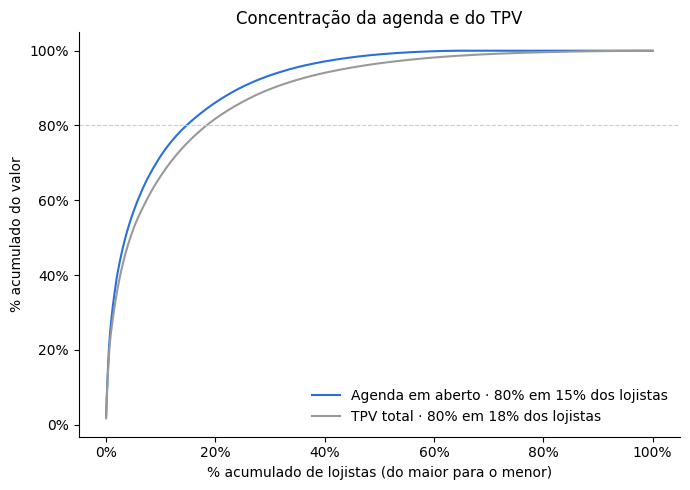

80% da agenda em aberto está em 14.8% dos lojistas; 80% do TPV, em 18.4%.


In [0]:
def pareto(serie):
    """Fração acumulada de lojistas (x) vs. fração acumulada do valor (y), do maior para o menor."""
    valores = np.sort(serie.fillna(0).to_numpy())[::-1]
    y = np.cumsum(valores) / valores.sum()
    x = np.arange(1, len(valores) + 1) / len(valores)
    pct_lojistas_80 = x[np.searchsorted(y, 0.80)]
    return x, y, pct_lojistas_80

x_ag, y_ag, p80_ag = pareto(metricas["agenda_aberta"])
x_tpv, y_tpv, p80_tpv = pareto(metricas["tpv_total"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x_ag, y_ag, color="#2a6fdb", label=f"Agenda em aberto · 80% em {p80_ag:.0%} dos lojistas")
ax.plot(x_tpv, y_tpv, color="#999999", label=f"TPV total · 80% em {p80_tpv:.0%} dos lojistas")
ax.axhline(0.8, color="#cccccc", linewidth=0.8, linestyle="--")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("% acumulado de lojistas (do maior para o menor)")
ax.set_ylabel("% acumulado do valor")
ax.set_title("Concentração da agenda e do TPV")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"80% da agenda em aberto está em {p80_ag:.1%} dos lojistas; 80% do TPV, em {p80_tpv:.1%}.")

## 5.3. Mix de pagamento e prazo por categoria

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_categoria_resumo AS
WITH vendas AS (
  SELECT
    categoria,
    count(DISTINCT seller_id) AS lojistas,
    sum(valor_venda) AS tpv_total,
    sum(CASE WHEN meio_pagamento = 'debito' THEN valor_venda ELSE 0 END) / sum(valor_venda) AS pct_debito,
    sum(CASE WHEN meio_pagamento = 'credito_avista' THEN valor_venda ELSE 0 END) / sum(valor_venda) AS pct_credito_avista,
    sum(CASE WHEN meio_pagamento = 'credito_parcelado' THEN valor_venda ELSE 0 END) / sum(valor_venda) AS pct_credito_parcelado,
    sum(CASE WHEN meio_pagamento = 'boleto' THEN valor_venda ELSE 0 END) / sum(valor_venda) AS pct_boleto,
    sum(CASE WHEN meio_pagamento IN ('voucher', 'outros') THEN valor_venda ELSE 0 END) / sum(valor_venda) AS pct_voucher_outros,
    sum(CASE WHEN payment_type = 'credit_card' THEN valor_venda * parcelas END)
      / nullif(sum(CASE WHEN payment_type = 'credit_card' THEN valor_venda END), 0) AS parcelas_media_credito,
    sum(CASE WHEN payment_type = 'credit_card' THEN valor_venda * p.prazo_dias * (parcelas + 1) / 2 END)
      / nullif(sum(CASE WHEN payment_type = 'credit_card' THEN valor_venda END), 0) AS prazo_medio_contratado_dias
  FROM vendas_ate_corte
  CROSS JOIN params p
  GROUP BY categoria
),
aberta AS (
  SELECT
    a.categoria,
    sum(a.valor_parcela) AS agenda_aberta,
    sum(a.valor_parcela * datediff(a.data_liquidacao, p.data_corte)) / sum(a.valor_parcela) AS prazo_medio_aberto_dias
  FROM workspace.olist.gold_f_agenda a
  CROSS JOIN params p
  WHERE a.data_venda <= p.data_corte AND a.data_liquidacao > p.data_corte
  GROUP BY a.categoria
)
SELECT
  v.*,
  coalesce(a.agenda_aberta, 0) AS agenda_aberta,
  a.prazo_medio_aberto_dias
FROM vendas v
LEFT JOIN aberta a USING (categoria)

num_affected_rows,num_inserted_rows


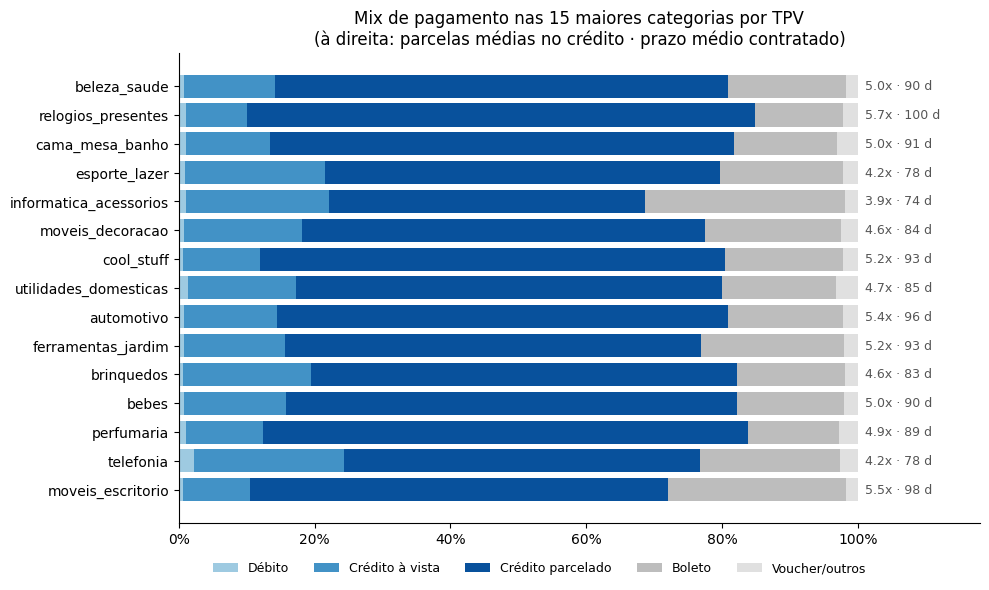

In [0]:
cat = (
    spark.table("workspace.olist.gold_categoria_resumo")
    .orderBy("tpv_total", ascending=False)
    .limit(15)
    .toPandas()
    .iloc[::-1]  # maior no topo do gráfico
)

colunas = [
    ("pct_debito", "Débito", "#9ecae1"),
    ("pct_credito_avista", "Crédito à vista", "#4292c6"),
    ("pct_credito_parcelado", "Crédito parcelado", "#08519c"),
    ("pct_boleto", "Boleto", "#bdbdbd"),
    ("pct_voucher_outros", "Voucher/outros", "#e0e0e0"),
]

fig, ax = plt.subplots(figsize=(10, 6))
esquerda = np.zeros(len(cat))
for col, nome, cor in colunas:
    ax.barh(cat["categoria"], cat[col], left=esquerda, color=cor, label=nome)
    esquerda += cat[col].to_numpy()
for i, (pm, pz) in enumerate(zip(cat["parcelas_media_credito"], cat["prazo_medio_contratado_dias"])):
    ax.text(1.01, i, f"{pm:.1f}x · {pz:.0f} d", va="center", fontsize=9, color="#555555")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1.18)
ax.set_title("Mix de pagamento nas 15 maiores categorias por TPV\n(à direita: parcelas médias no crédito · prazo médio contratado)")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.06), fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Categorias que mais "esperam" pelo dinheiro

Ordenadas pelo prazo médio contratado, entre as categorias com TPV relevante (acima da mediana). São candidatas naturais a uma oferta de antecipação.

In [0]:
%sql
SELECT
  categoria,
  lojistas,
  round(tpv_total, 0)                    AS tpv_total,
  round(pct_credito_parcelado, 3)        AS pct_credito_parcelado,
  round(parcelas_media_credito, 2)       AS parcelas_media_credito,
  round(prazo_medio_contratado_dias, 0)  AS prazo_medio_contratado_dias,
  round(agenda_aberta, 0)                AS agenda_aberta,
  round(prazo_medio_aberto_dias, 0)      AS prazo_medio_aberto_dias
FROM workspace.olist.gold_categoria_resumo
WHERE tpv_total >= (SELECT percentile_approx(tpv_total, 0.5) FROM workspace.olist.gold_categoria_resumo)
ORDER BY prazo_medio_contratado_dias DESC
LIMIT 15

categoria,lojistas,tpv_total,pct_credito_parcelado,parcelas_media_credito,prazo_medio_contratado_dias,agenda_aberta,prazo_medio_aberto_dias
portateis_casa_forno_e_cafe,9,41631.0,0.832,8.78,147.0,26669.0,117.0
pcs,6,211624.0,0.806,7.92,134.0,40185.0,102.0
instrumentos_musicais,63,185092.0,0.71,6.84,118.0,49458.0,94.0
eletrodomesticos_2,39,99035.0,0.778,6.85,118.0,40833.0,97.0
eletroportateis,92,187114.0,0.702,6.72,116.0,40425.0,87.0
agro_industria_e_comercio,17,64095.0,0.606,6.61,114.0,13870.0,72.0
casa_conforto,20,61431.0,0.7,6.32,110.0,9567.0,83.0
moveis_sala,50,71271.0,0.656,6.2,108.0,14116.0,92.0
construcao_ferramentas_construcao,96,120245.0,0.699,6.02,105.0,50252.0,90.0
relogios_presentes,87,1112847.0,0.748,5.66,100.0,272163.0,73.0


## 5.4. Atividade dos lojistas: cohort por mês da primeira venda

Cada linha é o grupo de lojistas que fez a primeira venda num mês. Cada coluna mostra quantos % deles venderam *n* meses depois. Para antecipação, importa porque um lojista que some deixa de gerar agenda.

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_cohort_sellers AS
WITH atividade AS (
  SELECT DISTINCT seller_id, trunc(data_venda, 'MM') AS mes
  FROM vendas_ate_corte
),
primeira AS (
  SELECT seller_id, min(mes) AS cohort_mes
  FROM atividade
  GROUP BY seller_id
),
contagem AS (
  SELECT
    p.cohort_mes,
    CAST(months_between(a.mes, p.cohort_mes) AS INT) AS meses_desde,
    count(DISTINCT a.seller_id) AS lojistas_ativos
  FROM atividade a
  JOIN primeira p USING (seller_id)
  GROUP BY p.cohort_mes, CAST(months_between(a.mes, p.cohort_mes) AS INT)
)
SELECT
  cohort_mes,
  meses_desde,
  lojistas_ativos,
  max(CASE WHEN meses_desde = 0 THEN lojistas_ativos END) OVER (PARTITION BY cohort_mes) AS tamanho_cohort,
  lojistas_ativos
    / max(CASE WHEN meses_desde = 0 THEN lojistas_ativos END) OVER (PARTITION BY cohort_mes) AS pct_ativos
FROM contagem

num_affected_rows,num_inserted_rows


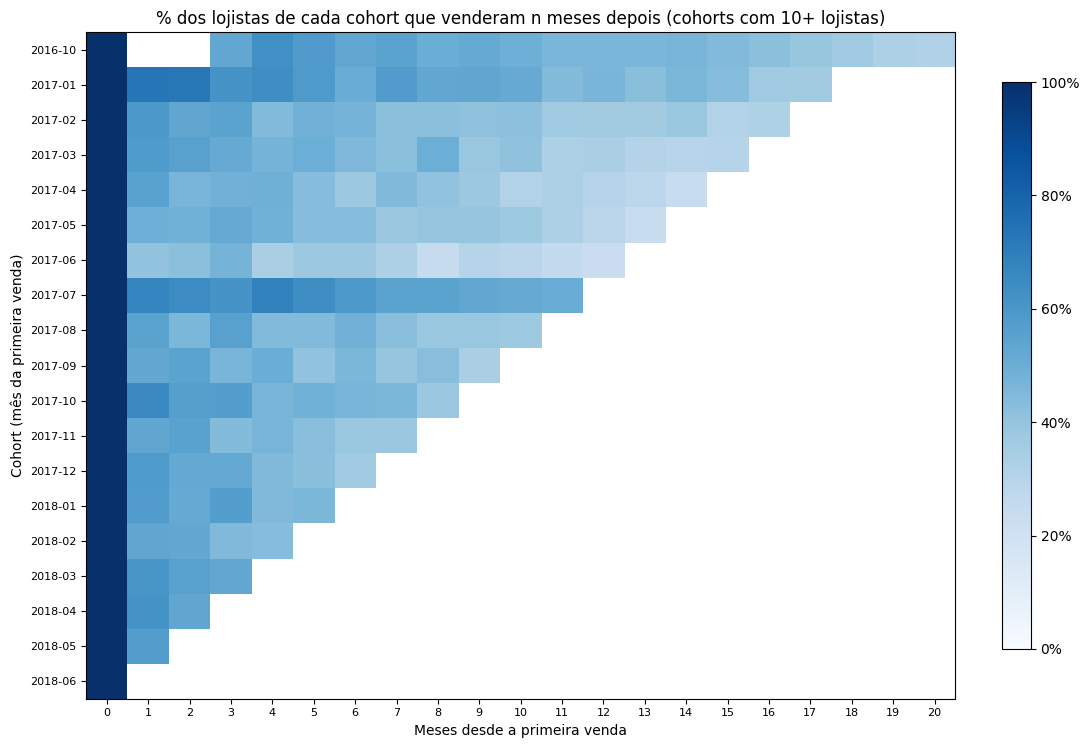

Mês 1: 58.1% dos lojistas ativos
Mês 3: 52.5% dos lojistas ativos
Mês 6: 45.8% dos lojistas ativos


In [0]:
coh = spark.table("workspace.olist.gold_cohort_sellers").toPandas()
coh = coh[coh["tamanho_cohort"] >= 10]  # cohorts muito pequenos distorcem a leitura
matriz = coh.pivot(index="cohort_mes", columns="meses_desde", values="pct_ativos").sort_index()

fig, ax = plt.subplots(figsize=(11, 0.32 * len(matriz) + 1.5))
im = ax.imshow(matriz.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(matriz)))
ax.set_yticklabels([d.strftime("%Y-%m") for d in matriz.index], fontsize=8)
ax.set_xticks(range(len(matriz.columns)))
ax.set_xticklabels(matriz.columns, fontsize=8)
ax.set_xlabel("Meses desde a primeira venda")
ax.set_ylabel("Cohort (mês da primeira venda)")
ax.set_title("% dos lojistas de cada cohort que venderam n meses depois (cohorts com 10+ lojistas)")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0), fraction=0.03)
plt.tight_layout()
plt.show()

# Leitura resumida: atividade média no mês 1, 3 e 6, ponderada pelo tamanho do cohort
for m in (1, 3, 6):
    sub = coh[coh["meses_desde"] == m]
    if len(sub):
        print(f"Mês {m}: {np.average(sub['pct_ativos'], weights=sub['tamanho_cohort']):.1%} dos lojistas ativos")

## 5.5. Segmentação por regra

As regras vêm do roteiro e são avaliadas **nesta ordem** (o primeiro critério atendido define o segmento):

| Ordem | Segmento | Regra | Hipótese de produto |
| --- | --- | --- | --- |
| 1 | Grandes parceladores | Top 20% por agenda em aberto **e** mais de 50% do TPV parcelado | Maior receita; alvo de taxa negociada |
| 2 | À vista | Menos de 20% do TPV parcelado | Pouca agenda; fora do foco |
| 3 | Médios recorrentes | Vendas em pelo menos 3 dos últimos 6 meses | Melhor alvo para antecipação automática |
| 4 | Grandes ocasionais | Agenda em aberto **e** mais de 50% do TPV parcelado **e** prazo médio contratado ≥ 90 dias | Venda grande, parcelada e demorada, mas sem recorrência; antecipação com limite inicial conservador |
| 5 | Pequenos ou esporádicos | O restante | Baixa receita; oferta self-service |

O segmento 4 foi aberto depois que o k-means (notebook 06, seção 6.6) mostrou o cluster "prazo longo · ticket alto" espalhado entre "Pequenos ou esporádicos" e "Grandes parceladores": são esporádicos no calendário, mas grandes na venda — ~234 lojistas com 45% da agenda do antigo segmento "pequenos".

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_seller_segmento AS
WITH ranking AS (
  SELECT
    m.*,
    percent_rank() OVER (ORDER BY m.agenda_aberta DESC) AS pr_agenda
  FROM workspace.olist.gold_seller_metricas m
)
SELECT
  r.seller_id,
  r.pr_agenda,
  CASE
    WHEN r.agenda_aberta > 0
     AND r.pr_agenda < p.seg_top_agenda
     AND r.pct_parcelado > p.seg_min_parcelado THEN 'Grandes parceladores'
    WHEN coalesce(r.pct_parcelado, 0) < p.seg_max_parcelado_avista THEN 'À vista'
    WHEN r.meses_ativos_janela >= p.seg_min_meses_ativos THEN 'Médios recorrentes'
    -- Grandes ocasionais (5º segmento): esporádico no calendário, grande na venda.
    -- Origem: cluster "prazo longo · ticket alto" do k-means (notebook 06, seção 6.6).
    WHEN r.agenda_aberta > 0
     AND r.pct_parcelado > p.seg_min_parcelado
     AND r.prazo_medio_contratado_dias >= p.seg_min_prazo_ocasionais THEN 'Grandes ocasionais'
    ELSE 'Pequenos ou esporádicos'
  END AS segmento_regra
FROM ranking r
CROSS JOIN params p

num_affected_rows,num_inserted_rows


In [0]:
%sql
CREATE OR REPLACE TABLE workspace.olist.gold_segmento_resumo AS
SELECT
  s.segmento_regra,
  count(*) AS lojistas,
  count(*) / sum(count(*)) OVER () AS pct_lojistas,
  sum(m.tpv_total) AS tpv_total,
  sum(m.tpv_total) / sum(sum(m.tpv_total)) OVER () AS pct_tpv,
  sum(m.agenda_aberta) AS agenda_aberta,
  sum(m.agenda_aberta) / sum(sum(m.agenda_aberta)) OVER () AS pct_agenda,
  sum(m.tpv_parcelado) / sum(m.tpv_total) AS pct_parcelado,
  percentile_approx(m.ticket_medio, 0.5) AS ticket_mediano,
  sum(m.tpv_credito * m.prazo_medio_contratado_dias)
    / nullif(sum(CASE WHEN m.prazo_medio_contratado_dias IS NOT NULL THEN m.tpv_credito END), 0) AS prazo_medio_contratado_dias,
  avg(m.meses_ativos_janela) AS meses_ativos_janela_medio
FROM workspace.olist.gold_seller_segmento s
JOIN workspace.olist.gold_seller_metricas m USING (seller_id)
GROUP BY s.segmento_regra

num_affected_rows,num_inserted_rows


In [0]:
display(spark.table("workspace.olist.gold_segmento_resumo").orderBy("pct_agenda", ascending=False))

segmento_regra,lojistas,pct_lojistas,tpv_total,pct_tpv,agenda_aberta,pct_agenda,pct_parcelado,ticket_mediano,prazo_medio_contratado_dias,meses_ativos_janela_medio
Grandes parceladores,469,0.17261685682738315,8669439.743211437,0.6330791597621691,1904225.5697738514,0.7827100976857049,0.6962748802148165,213.25418604651165,95.90296507333207,4.547974413646055
Médios recorrentes,646,0.23776223776223776,3226673.13481577,0.23562532038081116,380574.50521714066,0.15643078891676346,0.48255026187015754,109.8125,68.62638723040587,4.442724458204334
Pequenos ou esporádicos,929,0.3419212366580788,1067974.1143624107,0.07798798711274602,72969.3900961868,0.029993231556614174,0.6375627402510254,117.54666666666667,91.73020093362771,0.6716899892357373
Grandes ocasionais,234,0.0861244019138756,503341.91,0.03675615528735946,59895.55169480521,0.02461938011028169,0.7620901709159834,219.54,115.09796874086263,1.047008547008547
À vista,439,0.16157526683842474,226655.96761038658,0.016551377456914103,15196.876023809511,0.006246501730635896,0.08002410080452178,78.2,36.22381372746221,0.9544419134396356


### Peso de cada segmento: lojistas vs. agenda

O gráfico que vai para o deck: a diferença entre as duas barras de cada segmento mostra onde está o valor e onde está o volume de lojistas.

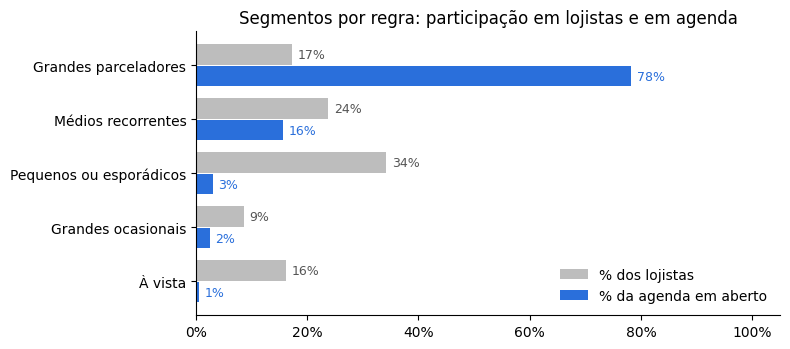

In [0]:
res = spark.table("workspace.olist.gold_segmento_resumo").toPandas().sort_values("pct_agenda")

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(res))
ax.barh(y + 0.2, res["pct_lojistas"], height=0.38, color="#bdbdbd", label="% dos lojistas")
ax.barh(y - 0.2, res["pct_agenda"], height=0.38, color="#2a6fdb", label="% da agenda em aberto")
for i, (pl, pa) in enumerate(zip(res["pct_lojistas"], res["pct_agenda"])):
    ax.text(pl + 0.01, i + 0.2, f"{pl:.0%}", va="center", fontsize=9, color="#555555")
    ax.text(pa + 0.01, i - 0.2, f"{pa:.0%}", va="center", fontsize=9, color="#2a6fdb")
ax.set_yticks(y)
ax.set_yticklabels(res["segmento_regra"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1.05)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Segmentos por regra: participação em lojistas e em agenda")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()